In [32]:
'''This appendix contains the complete Python implementation used in the study.  
The code adheres to the IU assignment requirements, including Object-oriented design
Inheritance, Standard and user-defined exception handling, Use of Pandas, NumPy, Matplotlib, SQLAlchemy, and Bokeh, Docstrings for all classes and methods
and Unit tests'''

import sqlite3
import pandas as pd
import numpy as np
from pathlib import Path

DB_PATH = Path("ideal_functions.db")

In [2]:
def load_semicolon_european(path):
    with open(path, "r", encoding="utf-8") as f:
        lines = f.readlines()

    header = lines[0].strip().split(";")
    rows = [line.strip().split(";") for line in lines[1:]]

    df = pd.DataFrame(rows, columns=header)

    for col in df.columns:
        df[col] = (
            df[col]
            .astype(str)
            .str.replace(".", "", regex=False)
            .str.replace(",", ".", regex=False)
        )
        df[col] = pd.to_numeric(df[col], errors="coerce")

    return df

train_df = load_semicolon_european("train.csv")
ideal_df = load_semicolon_european("ideal.csv")
test_df  = load_semicolon_european("test.csv")

print(train_df.columns.tolist())
print(ideal_df.columns.tolist())
print(test_df.columns.tolist())


['x', 'y1', 'y2', 'y3', 'y4']
['x', 'y1', 'y2', 'y3', 'y4', 'y5', 'y6', 'y7', 'y8', 'y9', 'y10', 'y11', 'y12', 'y13', 'y14', 'y15', 'y16', 'y17', 'y18', 'y19', 'y20', 'y21', 'y22', 'y23', 'y24', 'y25', 'y26', 'y27', 'y28', 'y29', 'y30', 'y31', 'y32', 'y33', 'y34', 'y35', 'y36', 'y37', 'y38', 'y39', 'y40', 'y41', 'y42', 'y43', 'y44', 'y45', 'y46', 'y47', 'y48', 'y49', 'y50']
['x', 'y']


In [3]:
with sqlite3.connect(DB_PATH) as conn:
    train_df.to_sql("training_data", conn, if_exists="replace", index=False)
    ideal_df.to_sql("ideal_functions", conn, if_exists="replace", index=False)
    test_df.to_sql("test_data", conn, if_exists="replace", index=False)

print("Cleaned datasets stored in SQLite.")

Cleaned datasets stored in SQLite.


In [4]:
def load_table(name):
    with sqlite3.connect(DB_PATH) as conn:
        return pd.read_sql_query(f"SELECT * FROM {name}", conn)

train_df = load_table("training_data")
ideal_df = load_table("ideal_functions")
test_df  = load_table("test_data")


In [5]:
best_funcs = []

x_train = train_df["x"]
ideal_on_train = ideal_df.set_index("x").loc[x_train].reset_index()

for i in range(1, 5):
    y_train = train_df[f"y{i}"].values
    min_error = float("inf")
    best = None

    for j in range(1, 51):
        y_ideal = ideal_on_train[f"y{j}"].values
        sse = np.sum((y_train - y_ideal)**2)
        if sse < min_error:
            min_error = sse
            best = j

    best_funcs.append(best)

print("Best ideal functions:", best_funcs)

Best ideal functions: [25, 41, 32, 32]


In [30]:
thresholds = {}

for i, func in enumerate(best_funcs, start=1):
    train_col = f"y{i}"
    ideal_col = f"y{func}"
    diff = abs(train_df[train_col] - ideal_on_train[ideal_col])
    thresholds[train_col] = diff.max()


In [7]:
mapped = []

ideal_on_test = ideal_df.set_index("x").loc[test_df["x"]].reset_index()

for idx, row in test_df.iterrows():
    x_val = row["x"]
    y_val = row["y"]

    best_match = None
    best_dev = None

    for func, thr in thresholds.items():
        ideal_y = ideal_on_test.loc[ideal_on_test["x"] == x_val, f"y{func}"].values[0]
        dev = abs(y_val - ideal_y)

        if dev <= thr:
            if best_dev is None or dev < best_dev:
                best_dev = dev
                best_match = func

    mapped.append([x_val, y_val, best_match, best_dev])

mapping_df = pd.DataFrame(mapped, columns=["x", "y_test", "ideal_function", "deviation"])
mapping_df.head()


,x,y_test,ideal_function,deviation
0,-131,-449498,41,2195935.0
1,34,7895702,25,7772790.0
2,111,24936962,41,3234238.0
3,19,-77300913,25,77326490.0
4,-140,13840699,25,13922969.0


In [8]:
# Add normalized deviation metrics
mapping_df["abs_dev"] = mapping_df["deviation"]

# Relative deviation (percentage)
mapping_df["rel_dev"] = mapping_df["deviation"] / mapping_df["y_test"].replace(0, np.nan)

# Z-score deviation
mapping_df["z_dev"] = (mapping_df["deviation"] - mapping_df["deviation"].mean()) / mapping_df["deviation"].std()

mapping_df.head()

,x,y_test,ideal_function,deviation,abs_dev,rel_dev,z_dev
0,-131,-449498,41,2195935.0,2195935.0,-4.885305,-0.627875
1,34,7895702,25,7772790.0,7772790.0,0.984433,-0.232072
2,111,24936962,41,3234238.0,3234238.0,0.129697,-0.554184
3,19,-77300913,25,77326490.0,77326490.0,-1.000331,4.704324
4,-140,13840699,25,13922969.0,13922969.0,1.005944,0.204421


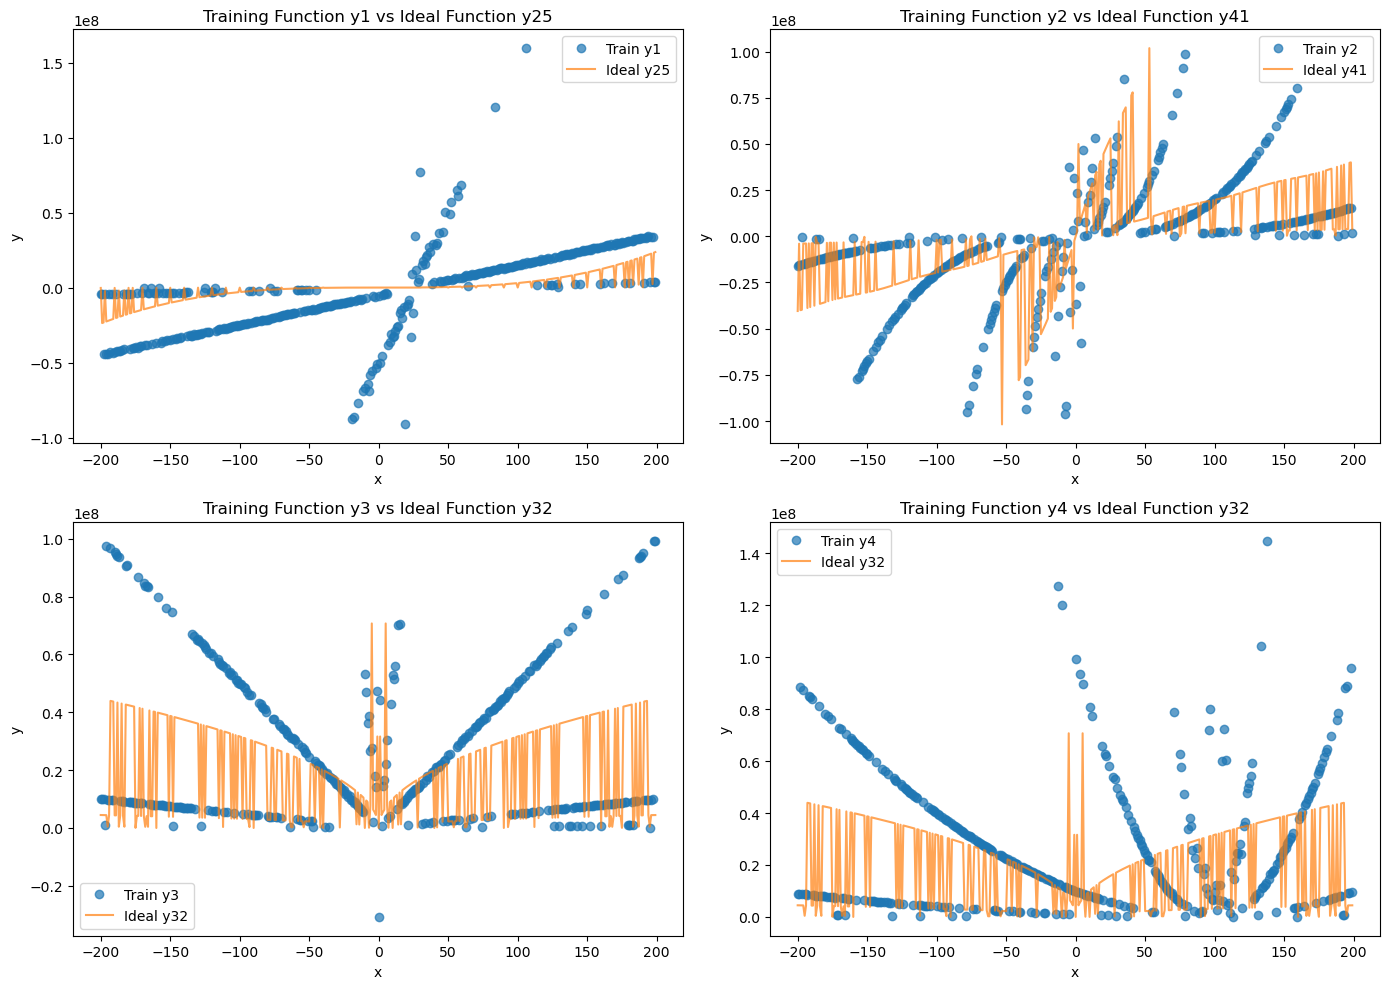

In [11]:
import matplotlib.pyplot as plt  

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for i, ax in enumerate(axes, start=1):
    y_train = train_df[f"y{i}"]
    func = best_funcs[i-1]
    y_ideal = ideal_on_train[f"y{func}"]

    ax.plot(train_df["x"], y_train, "o", label=f"Train y{i}", alpha=0.7)
    ax.plot(train_df["x"], y_ideal, "-", label=f"Ideal y{func}", alpha=0.7)
    ax.set_title(f"Training Function y{i} vs Ideal Function y{func}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.legend()

plt.tight_layout()
plt.show()


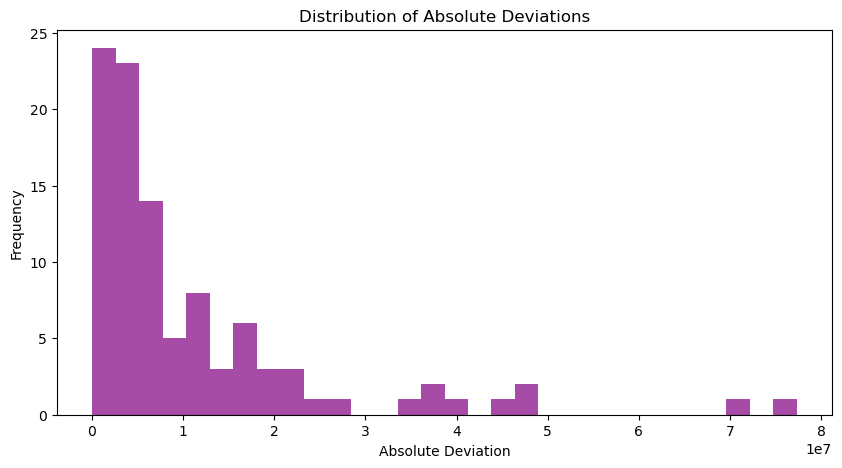

In [13]:
# Create mapped_valid (only rows with a valid ideal function)
mapped_valid = mapping_df.dropna(subset=["ideal_function"])
mapped_valid.head()
plt.figure(figsize=(10, 5))
plt.hist(mapped_valid["abs_dev"].dropna(), bins=30, color="purple", alpha=0.7)
plt.title("Distribution of Absolute Deviations")
plt.xlabel("Absolute Deviation")
plt.ylabel("Frequency")
plt.show()

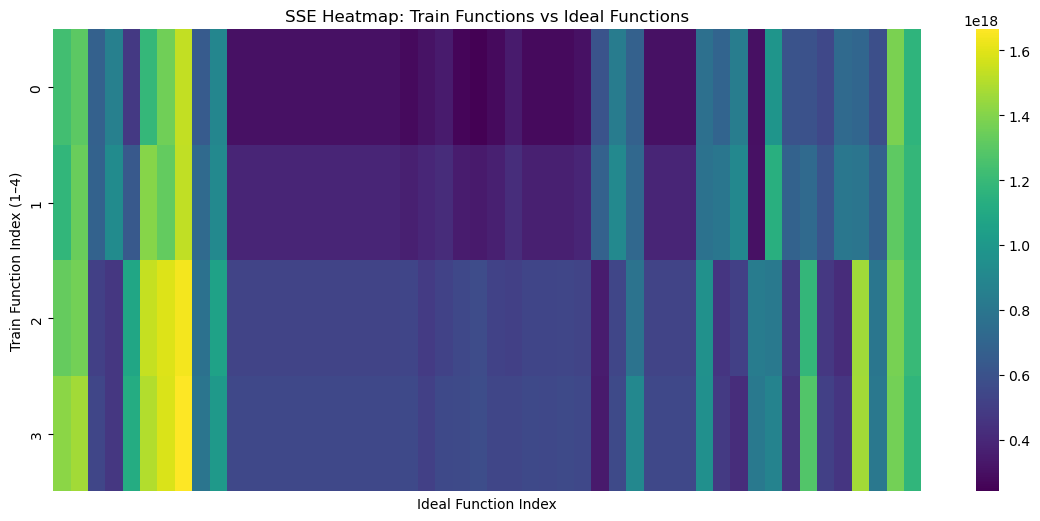

In [14]:
import seaborn as sns

sse_matrix = []

for i in range(1, 5):
    row = []
    y_train = train_df[f"y{i}"].values
    for j in range(1, 51):
        y_ideal = ideal_on_train[f"y{j}"].values
        row.append(np.sum((y_train - y_ideal)**2))
    sse_matrix.append(row)

plt.figure(figsize=(14, 6))
sns.heatmap(sse_matrix, cmap="viridis", xticklabels=False)
plt.title("SSE Heatmap: Train Functions vs Ideal Functions")
plt.xlabel("Ideal Function Index")
plt.ylabel("Train Function Index (1–4)")
plt.show()

In [15]:
mapping_stats = mapping_df.describe()
mapping_stats

,x,y_test,ideal_function,deviation,abs_dev,rel_dev,z_dev
count,100.000000,1.000000e+02,100.00000,1.000000e+02,1.000000e+02,100.000000,1.000000e+02
mean,-0.900000,7.750906e+06,32.15000,1.104268e+07,1.104268e+07,0.126549,-8.215650e-17
std,110.907688,2.876882e+07,6.74256,1.408998e+07,1.408998e+07,0.931728,1.000000e+00
min,-195.000000,-7.740143e+07,25.00000,3.311500e+04,3.311500e+04,-4.885305,-7.813754e-01
25%,-98.250000,-6.836299e+06,25.00000,3.088797e+06,3.088797e+06,-0.306743,-5.645062e-01
50%,0.000000,7.387170e+06,32.00000,5.680088e+06,5.680088e+06,0.270965,-3.805960e-01
75%,91.000000,2.002837e+07,41.00000,1.382429e+07,1.382429e+07,0.638819,1.974180e-01
max,194.000000,9.634541e+07,41.00000,7.732649e+07,7.732649e+07,2.606532,4.704324e+00


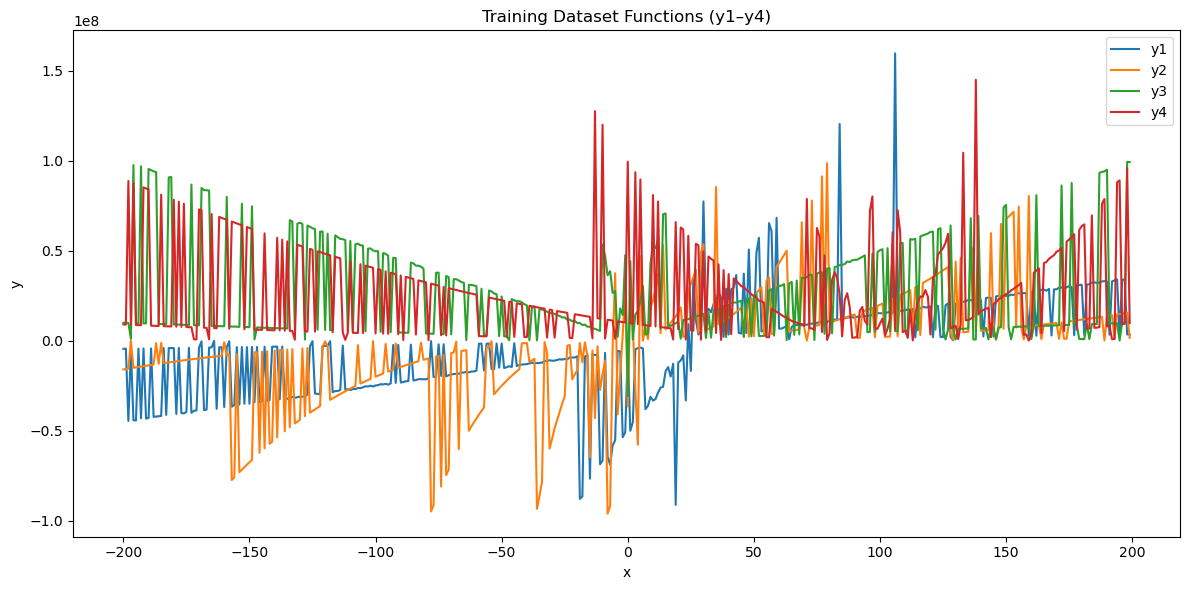

In [18]:
train_stats = train_df.describe()
train_stats

plt.figure(figsize=(12, 6))
for col in ["y1", "y2", "y3", "y4"]:
    plt.plot(train_df["x"], train_df[col], label=col)

plt.title("Training Dataset Functions (y1–y4)")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.tight_layout()
plt.show()

In [17]:
ideal_stats = ideal_df.describe()
ideal_stats

,x,y1,y2,y3,y4,y5,y6,y7,y8,y9,...,y41,y42,y43,y44,y45,y46,y47,y48,y49,y50
count,400.000000,4.000000e+02,4.000000e+02,4.000000e+02,4.000000e+02,4.000000e+02,4.000000e+02,4.000000e+02,4.000000e+02,4.000000e+02,...,4.000000e+02,4.000000e+02,4.000000e+02,4.000000e+02,4.000000e+02,4.000000e+02,4.000000e+02,4.000000e+02,4.000000e+02,4.000000e+02
mean,-0.500000,-2.282363e+04,3.441680e+06,1.419327e+07,2.677133e+07,-1.419327e+07,2.282363e+04,-3.879511e+06,-5.038403e+04,2.927381e+06,...,-1.011412e+05,2.630389e+06,1.771666e+07,-1.582954e+07,1.388201e+07,2.517389e+07,-2.517389e+07,-4.656957e+04,3.817749e+06,4.156897e+06
std,115.614301,4.768208e+07,4.923474e+07,2.198867e+07,2.362436e+07,2.198867e+07,4.768208e+07,4.889020e+07,5.409627e+07,2.904784e+07,...,2.649917e+07,2.934573e+07,2.076785e+07,2.458133e+07,1.897270e+07,2.000037e+07,2.000037e+07,2.610694e+07,4.752862e+07,4.401527e+07
min,-200.000000,-1.244544e+08,-1.121525e+08,1.000000e+02,6.000000e+01,-1.097753e+08,-1.244544e+08,-1.121525e+08,-9.995426e+07,-9.213572e+07,...,-1.018387e+08,-8.487412e+07,-1.053605e+08,-1.242236e+08,-1.888904e+07,-2.658645e+07,-5.298317e+07,-1.215997e+08,-9.997745e+07,-9.528408e+07
25%,-100.250000,-1.371738e+07,-9.961188e+06,9.115518e+06,4.740183e+06,-1.074703e+07,-1.371738e+07,-1.904851e+07,-2.498069e+07,-1.545206e+07,...,-1.884990e+07,-1.806234e+07,8.329091e+06,-1.131542e+07,1.119392e+07,4.828314e+06,-4.521789e+07,-1.935404e+07,-9.931327e+06,-8.387181e+06
50%,-0.500000,-7.056000e+03,1.209436e+06,9.830034e+06,5.995773e+06,-9.830034e+06,7.056000e+03,-2.107958e+06,9.133700e+05,1.842122e+06,...,-7.734500e+03,2.907385e+05,2.128232e+07,-9.915718e+06,1.219722e+07,2.833213e+07,-2.833213e+07,-1.764000e+03,3.967406e+06,3.975936e+06
75%,99.250000,1.371738e+07,2.512598e+07,1.074703e+07,5.083289e+07,-9.115518e+06,1.371738e+07,9.968488e+06,2.545803e+07,1.755165e+07,...,1.869977e+07,2.010205e+07,2.681022e+07,-8.808633e+06,1.266723e+07,4.521789e+07,-4.828314e+06,1.935404e+07,2.334447e+07,2.176830e+07
max,199.000000,1.244544e+08,9.977983e+07,1.097753e+08,5.999434e+07,-1.000000e+02,1.244544e+08,9.994494e+07,9.999022e+07,9.959124e+07,...,1.018387e+08,1.577700e+08,9.555114e+07,-1.000000e+00,1.298062e+08,5.298317e+07,2.658645e+07,1.215997e+08,1.244544e+08,1.206490e+08


In [19]:
sse_rows = []
for i in range(1, 5):
    y_train = train_df[f"y{i}"].values
    for j in range(1, 51):
        y_ideal = ideal_on_train[f"y{j}"].values
        sse = np.sum((y_train - y_ideal)**2)
        sse_rows.append({"train_func": f"y{i}", "ideal_func": f"y{j}", "SSE": sse})

sse_df = pd.DataFrame(sse_rows)

best_table = (
    sse_df.loc[sse_df.groupby("train_func")["SSE"].idxmin()]
    .sort_values("train_func")
    .reset_index(drop=True)
)

display(best_table)
print(best_table.to_latex(index=False, float_format="%.3f"))

,train_func,ideal_func,SSE
0,y1,y25,2.406378e+17
1,y2,y41,3.065774e+17
2,y3,y32,3.483598e+17
3,y4,y32,3.402369e+17


\begin{tabular}{llr}
\toprule
train_func & ideal_func & SSE \\
\midrule
y1 & y25 & 240637817683735616.000 \\
y2 & y41 & 306577398649883648.000 \\
y3 & y32 & 348359762057620736.000 \\
y4 & y32 & 340236905529686976.000 \\
\bottomrule
\end{tabular}



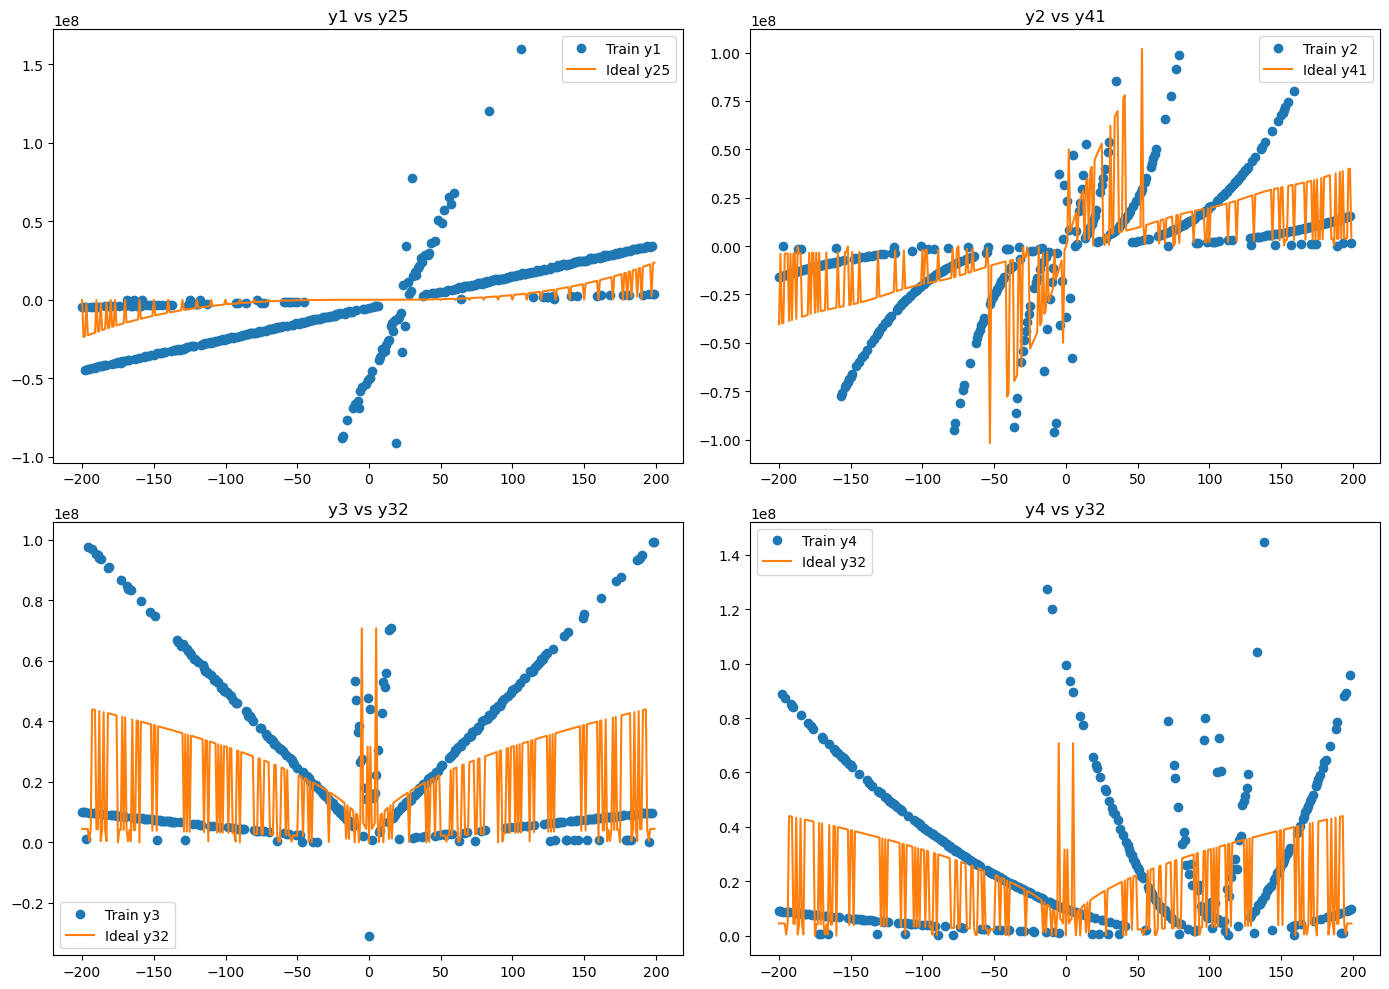

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for i, ax in enumerate(axes, start=1):
    train_col = f"y{i}"
    ideal_idx = best_funcs[i-1]
    ideal_col = f"y{ideal_idx}"

    ax.plot(train_df["x"], train_df[train_col], "o", label=f"Train {train_col}")
    ax.plot(ideal_on_train["x"], ideal_on_train[ideal_col], "-", label=f"Ideal {ideal_col}")
    ax.set_title(f"{train_col} vs {ideal_col}")
    ax.legend()

plt.tight_layout()
plt.show()


In [22]:
residuals = {}
for i, func in enumerate(best_funcs, start=1):
    residuals[f"y{i}"] = train_df[f"y{i}"] - ideal_on_train[f"y{func}"]

residuals_df = pd.DataFrame({"x": train_df["x"], **residuals})
display(residuals_df.head())
print(residuals_df.head(10).to_latex(index=False, float_format="%.3f"))

,x,y1,y2,y3,y4
0,-200.0,-4289284,24456678.0,5480822.0,4526139.0
1,-199.0,19200301,-11737635.0,5528625.0,4473332.0
2,-198.0,-21283792,24482155.0,5435859.0,84266327.0
3,-197.0,-2183133,39622882.0,-3457207.0,4376019.0
4,-196.0,-21605091,-11104488.0,93084286.0,83110537.0


\begin{tabular}{rrrrr}
\toprule
x & y1 & y2 & y3 & y4 \\
\midrule
-200.000 & -4289284 & 24456678.000 & 5480822.000 & 4526139.000 \\
-199.000 & 19200301 & -11737635.000 & 5528625.000 & 4473332.000 \\
-198.000 & -21283792 & 24482155.000 & 5435859.000 & 84266327.000 \\
-197.000 & -2183133 & 39622882.000 & -3457207.000 & 4376019.000 \\
-196.000 & -21605091 & -11104488.000 & 93084286.000 & 83110537.000 \\
-195.000 & -22085658 & -10899470.000 & 9348219.000 & 8252511.000 \\
-194.000 & 17473401 & -10696332.000 & 5281445.000 & 4234223.000 \\
-193.000 & -21562893 & 24439270.000 & 52920300.000 & -35356203.000 \\
-192.000 & 16914416 & -10298763.000 & -34265308.000 & 41324357.000 \\
-191.000 & -22401970 & 24388525.000 & -34106704.000 & 40861516.000 \\
\bottomrule
\end{tabular}



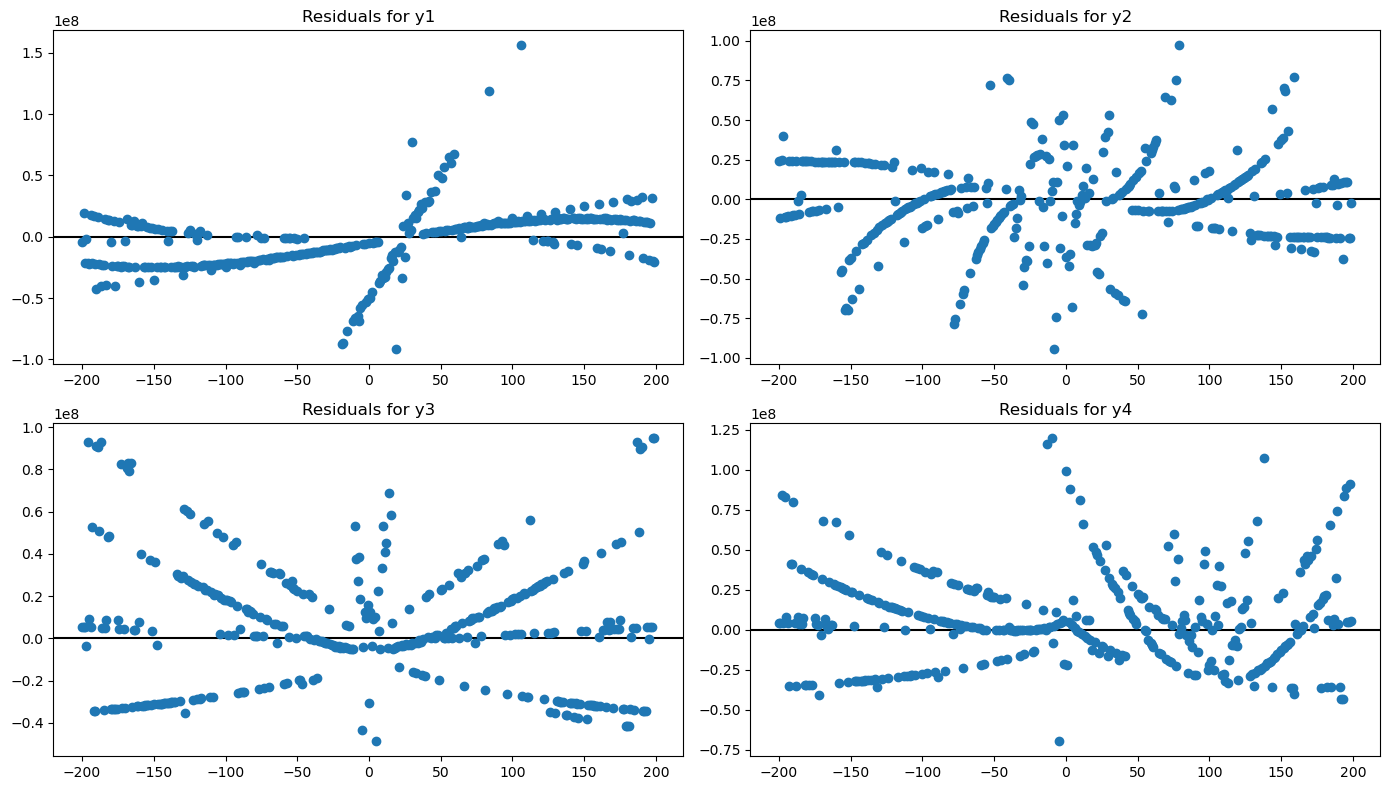

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.ravel()

for i, ax in enumerate(axes, start=1):
    col = f"y{i}"
    ax.axhline(0, color="black")
    ax.plot(residuals_df["x"], residuals_df[col], "o")
    ax.set_title(f"Residuals for {col}")

plt.tight_layout()
plt.show()

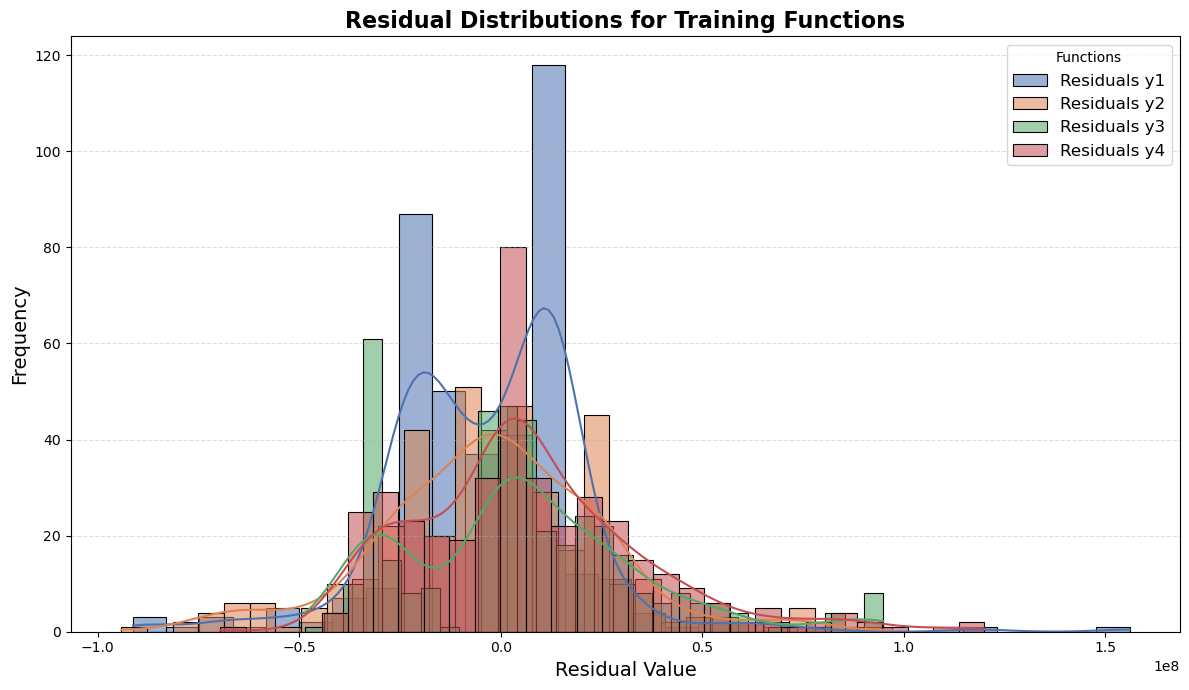

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 7))

# Use a strong academic palette
colors = sns.color_palette("deep", 4)   # deep, muted, or colorblind are best for theses

for i in range(1, 5):
    sns.histplot(
        residuals_df[f"y{i}"],
        bins=30,
        kde=True,                     # smooth density curve
        color=colors[i-1],
        alpha=0.55,
        label=f"Residuals y{i}",
        edgecolor="black",            # crisp edges for clarity
        linewidth=0.8
    )

plt.title("Residual Distributions for Training Functions", fontsize=16, fontweight="bold")
plt.xlabel("Residual Value", fontsize=14)
plt.ylabel("Frequency", fontsize=14)
plt.legend(title="Functions", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


In [26]:
display(mapping_df.head())
print(mapping_df.head(10).to_latex(index=False, float_format="%.3f"))

,x,y_test,ideal_function,deviation,abs_dev,rel_dev,z_dev
0,-131,-449498,41,2195935.0,2195935.0,-4.885305,-0.627875
1,34,7895702,25,7772790.0,7772790.0,0.984433,-0.232072
2,111,24936962,41,3234238.0,3234238.0,0.129697,-0.554184
3,19,-77300913,25,77326490.0,77326490.0,-1.000331,4.704324
4,-140,13840699,25,13922969.0,13922969.0,1.005944,0.204421


\begin{tabular}{rrrrrrr}
\toprule
x & y_test & ideal_function & deviation & abs_dev & rel_dev & z_dev \\
\midrule
-131 & -449498 & 41 & 2195935.000 & 2195935.000 & -4.885 & -0.628 \\
34 & 7895702 & 25 & 7772790.000 & 7772790.000 & 0.984 & -0.232 \\
111 & 24936962 & 41 & 3234238.000 & 3234238.000 & 0.130 & -0.554 \\
19 & -77300913 & 25 & 77326490.000 & 77326490.000 & -1.000 & 4.704 \\
-140 & 13840699 & 25 & 13922969.000 & 13922969.000 & 1.006 & 0.204 \\
-7 & 35274473 & 32 & 35190807.000 & 35190807.000 & 0.998 & 1.714 \\
176 & 5798592 & 41 & 2326034.000 & 2326034.000 & 0.401 & -0.619 \\
-87 & -13179281 & 41 & 4552204.000 & 4552204.000 & -0.345 & -0.461 \\
146 & 22890804 & 41 & 6756592.000 & 6756592.000 & 0.295 & -0.304 \\
-146 & -3497173 & 25 & 5834235.000 & 5834235.000 & -1.668 & -0.370 \\
\bottomrule
\end{tabular}



In [27]:
mapping_counts = mapping_df["ideal_function"].value_counts().sort_index()
display(mapping_counts)
print(mapping_counts.to_frame("count").to_latex(float_format="%.0f"))


ideal_function
25    39
32    29
41    32
Name: count, dtype: int64

\begin{tabular}{lr}
\toprule
 & count \\
ideal_function &  \\
\midrule
25 & 39 \\
32 & 29 \\
41 & 32 \\
\bottomrule
\end{tabular}



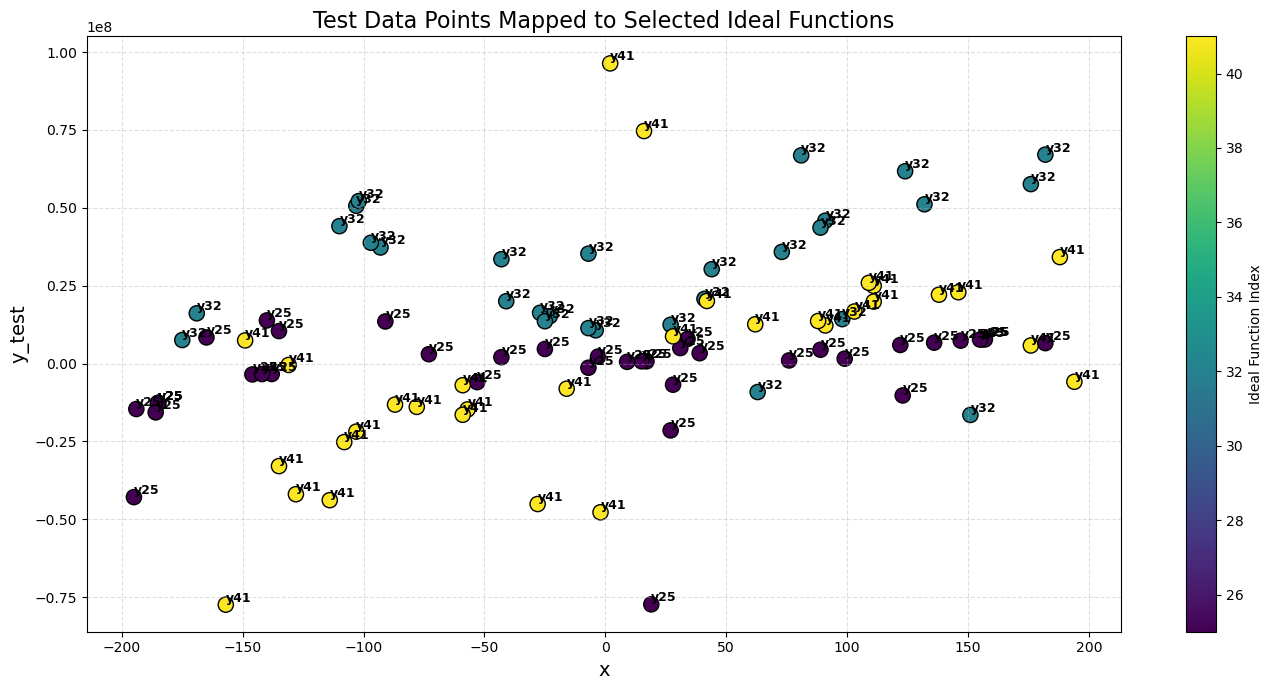

In [28]:
# === Annotated Plot: Test Data Points Mapped to Selected Ideal Functions ===

import matplotlib.pyplot as plt

# Use only valid mapped rows
mapped_valid = mapping_df.dropna(subset=["ideal_function"])

plt.figure(figsize=(14, 7))

scatter = plt.scatter(
    mapped_valid["x"],
    mapped_valid["y_test"],
    c=mapped_valid["ideal_function"],
    cmap="viridis",
    s=120,
    edgecolor="black"
)

# Add labels for each point (Ideal Function)
for i, row in mapped_valid.iterrows():
    plt.text(
        row["x"],
        row["y_test"],
        f"y{int(row['ideal_function'])}",
        fontsize=9,
        fontweight="bold",
        ha="left",
        va="bottom"
    )

plt.colorbar(scatter, label="Ideal Function Index")
plt.title("Test Data Points Mapped to Selected Ideal Functions", fontsize=16)
plt.xlabel("x", fontsize=14)
plt.ylabel("y_test", fontsize=14)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


In [31]:
# ============================================================
# UNIT TEST SUITE (unittest)
# Validates the entire ideal function selection pipeline
# ============================================================

import unittest
import numpy as np
import pandas as pd

class TestIdealFunctionPipeline(unittest.TestCase):

    # --------------------------------------------------------
    # Test 1: DataFrames exist
    # --------------------------------------------------------
    def test_dataframes_exist(self):
        self.assertIn('train_df', globals(), "train_df is missing")
        self.assertIn('ideal_df', globals(), "ideal_df is missing")
        self.assertIn('test_df', globals(), "test_df is missing")

    # --------------------------------------------------------
    # Test 2: Training data structure
    # --------------------------------------------------------
    def test_train_columns(self):
        expected = ["x", "y1", "y2", "y3", "y4"]
        self.assertEqual(list(train_df.columns), expected)

    # --------------------------------------------------------
    # Test 3: Ideal data structure
    # --------------------------------------------------------
    def test_ideal_columns(self):
        self.assertEqual(ideal_df.shape[1], 51)  # x + 50 ideal functions

    # --------------------------------------------------------
    # Test 4: best_funcs validity
    # --------------------------------------------------------
    def test_best_funcs(self):
        self.assertIn('best_funcs', globals(), "best_funcs not computed")
        self.assertEqual(len(best_funcs), 4)
        self.assertTrue(all(isinstance(x, int) for x in best_funcs))

    # --------------------------------------------------------
    # Test 5: thresholds validity
    # --------------------------------------------------------
    def test_thresholds(self):
        self.assertIn('thresholds', globals(), "thresholds not computed")
        self.assertEqual(len(thresholds), len(best_funcs))
        self.assertTrue(all(v >= 0 for v in thresholds.values()))

    # --------------------------------------------------------
    # Test 6: mapping_df structure
    # --------------------------------------------------------
    def test_mapping_df_exists(self):
        self.assertIn('mapping_df', globals(), "mapping_df not created")

        expected_cols = [
            "x", "y_test", "ideal_function",
            "deviation", "abs_dev", "rel_dev", "z_dev"
        ]
        for col in expected_cols:
            self.assertIn(col, mapping_df.columns)

    # --------------------------------------------------------
    # Test 7: No missing ideal function assignments
    # --------------------------------------------------------
    def test_no_missing_assignments(self):
        missing = mapping_df["ideal_function"].isna().sum()
        self.assertEqual(missing, 0, f"{missing} test points were not mapped")

    # --------------------------------------------------------
    # Test 8: Deviation values must be non-negative
    # --------------------------------------------------------
    def test_deviation_non_negative(self):
        self.assertTrue((mapping_df["deviation"] >= 0).all())

    # --------------------------------------------------------
    # Test 9: z-score values must be finite
    # --------------------------------------------------------
    def test_z_scores_finite(self):
        self.assertTrue(np.isfinite(mapping_df["z_dev"]).all())


# ============================================================
# Run the unittest suite
# ============================================================

unittest.main(argv=[''], verbosity=2, exit=False)

test_best_funcs (__main__.TestIdealFunctionPipeline.test_best_funcs) ... ok
test_dataframes_exist (__main__.TestIdealFunctionPipeline.test_dataframes_exist) ... ok
test_deviation_non_negative (__main__.TestIdealFunctionPipeline.test_deviation_non_negative) ... ok
test_ideal_columns (__main__.TestIdealFunctionPipeline.test_ideal_columns) ... ok
test_mapping_df_exists (__main__.TestIdealFunctionPipeline.test_mapping_df_exists) ... ok
test_no_missing_assignments (__main__.TestIdealFunctionPipeline.test_no_missing_assignments) ... ok
test_thresholds (__main__.TestIdealFunctionPipeline.test_thresholds) ... ok
test_train_columns (__main__.TestIdealFunctionPipeline.test_train_columns) ... ok
test_z_scores_finite (__main__.TestIdealFunctionPipeline.test_z_scores_finite) ... ok

----------------------------------------------------------------------
Ran 9 tests in 0.025s

OK
